In [1]:
import os

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [9]:
def get_ea_data(path, mix_rules):
    ea_data = pd.DataFrame(
        columns=["seed", "Mixing rule", "Beta", "t", "A_n", "delta_n"]
    )
    files = os.listdir(path)
    for f in files:
        pd_data = pd.read_csv(f"{path}/{f}")
        ea_data = pd.concat([ea_data, pd_data[pd_data["Mixing rule"].isin(mix_rules)]]) 
    return ea_data

sub_sampling_rate = 1
path = f"results/srate{sub_sampling_rate}"

mixing_rules = [
    #"avg",
    #"softmax",
    "stoch",
    "stoch_gene_wise",
    #"dot",
    "stoch_softmax",
    "stoch_softmax_gene_wise",
    "negotiate",
    "new_negotiate",
]

ea_data = get_ea_data(path, mixing_rules)

print(ea_data.columns)

Index(['seed', 'Mixing rule', 'Beta', 't', 'A_n', 'delta_n', 'delta_p'], dtype='object')


/tmp/ipykernel_545349/281620551.py:8: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  ea_data = pd.concat([ea_data, pd_data[pd_data["Mixing rule"].isin(mix_rules)]])


In [10]:
#sns.lineplot(data=ea_data, x="t", y="A_n", hue="Mixing rule", style="Beta", palette="tab10")

/tmp/ipykernel_545349/4004790184.py:13: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(data=pd_data, x="t", y="A_n", palette="tab10")


<Axes: title={'center': 'Total evolutionary activity over time'}, xlabel='Time', ylabel='Total evolutionary activity $A_n$'>

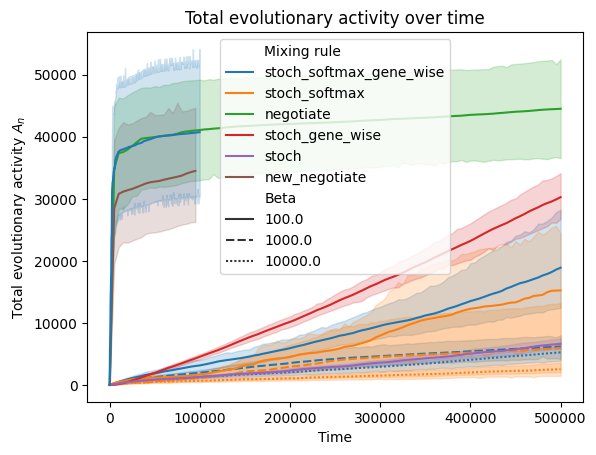

In [11]:
sub_sampled_ea = ea_data[ea_data["t"] % 5000 == 0]
sns.lineplot(data=sub_sampled_ea, x="t", y="A_n", hue="Mixing rule", style="Beta", palette="tab10")
plt.title("Total evolutionary activity over time")
plt.xlabel("Time")
plt.ylabel("Total evolutionary activity $A_n$")
#Make legend smaller
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), ncol=1)


plt.savefig("ea_over_time_new.png", dpi=300, bbox_inches='tight')

pd_data = pd.read_csv(f"ea_data_negotiate_100_srate1.csv")
sns.lineplot(data=pd_data, x="t", y="A_n", palette="tab10")

<Axes: xlabel='t', ylabel='A_n'>

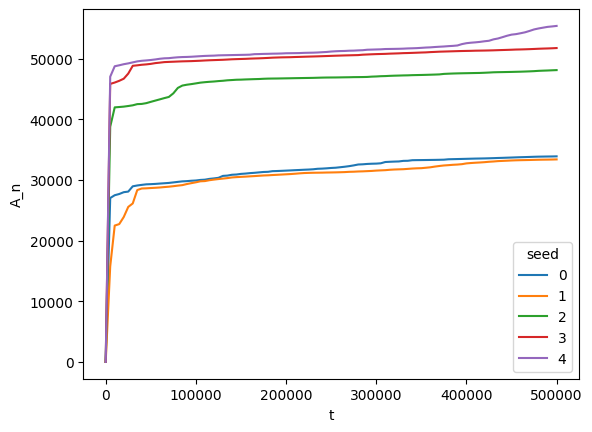

In [5]:
sns.lineplot(data=sub_sampled_ea[sub_sampled_ea["Mixing rule"]=="negotiate"], x="t", y="A_n", hue="seed", palette="tab10")

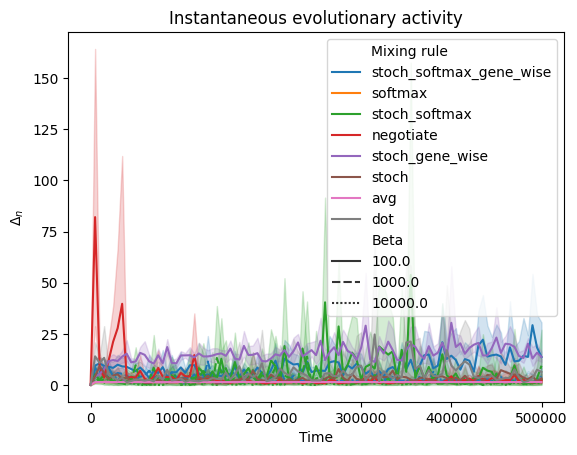

In [6]:
sub_sampled_ea = ea_data[ea_data["t"] % 5000 == 0]
sns.lineplot(data=sub_sampled_ea, x="t", y="delta_n", hue="Mixing rule", style="Beta", palette="tab10")
plt.title("Instantaneous evolutionary activity")
plt.xlabel("Time")
plt.ylabel("$\Delta_n$")
#Make legend smaller
plt.savefig("delta_n_over_time.png", dpi=300, bbox_inches='tight')

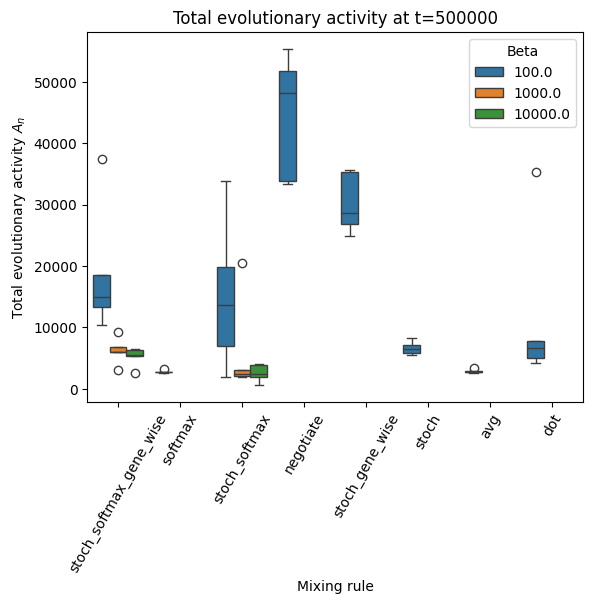

In [7]:
final_ea = ea_data[ea_data["t"] == 500000]
sns.boxplot(data=final_ea, x="Mixing rule", y="A_n", hue="Beta", palette="tab10")
plt.xticks(rotation=60)
plt.title("Total evolutionary activity at t=500000")
plt.ylabel("Total evolutionary activity $A_n$")
plt.savefig("ea_final.png", dpi=300, bbox_inches='tight')

Text(0, 0.5, 'Number of unique genomes')

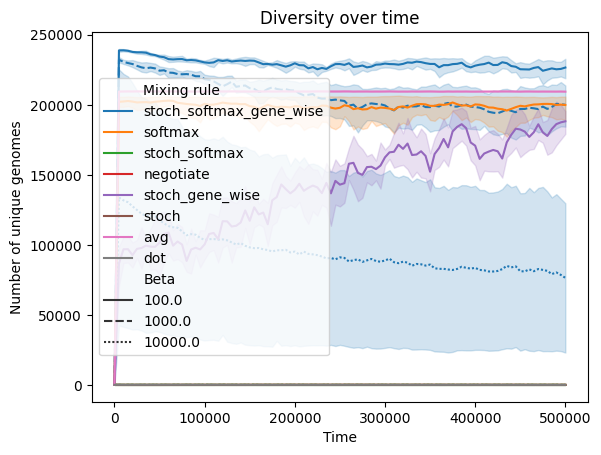

In [8]:
sns.lineplot(data=sub_sampled_ea, x="t", y="delta_p", hue="Mixing rule", style="Beta", palette="tab10")

plt.title("Diversity over time")
plt.xlabel("Time")
plt.ylabel("Number of unique genomes")

## Influence of horizon

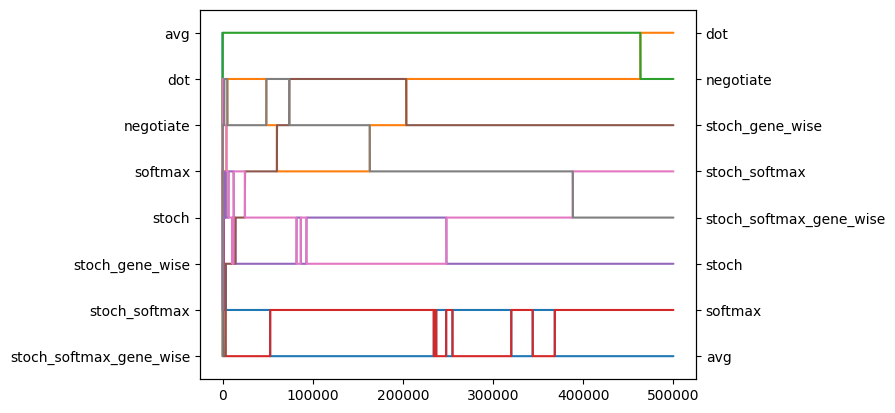

In [9]:
from flowlenia.vizutils import bumpchart
ea = ea_data[["A_n", "t", "Mixing rule"]].drop_duplicates(["Mixing rule", "t"])
# One column per mixing rule
ea = ea.pivot(index="t", columns="Mixing rule", values="A_n")
ea = ea.rank(axis=1, method="first", ascending=False, na_option="bottom", pct=True) * ea.shape[1]


bumpchart(ea, show_rank_axis=False, scatter=False, holes=False)
plt.show()

## Influence of sampling rate

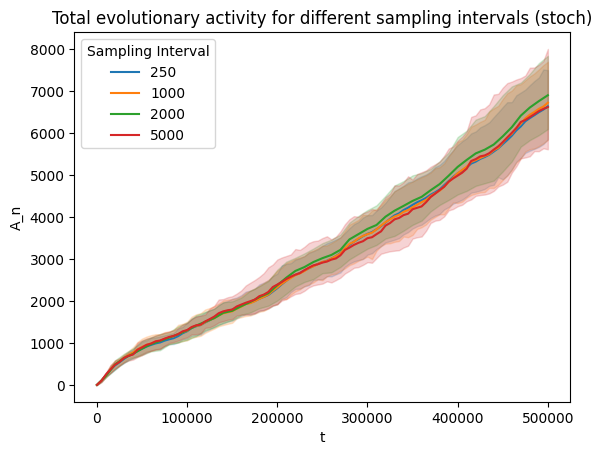

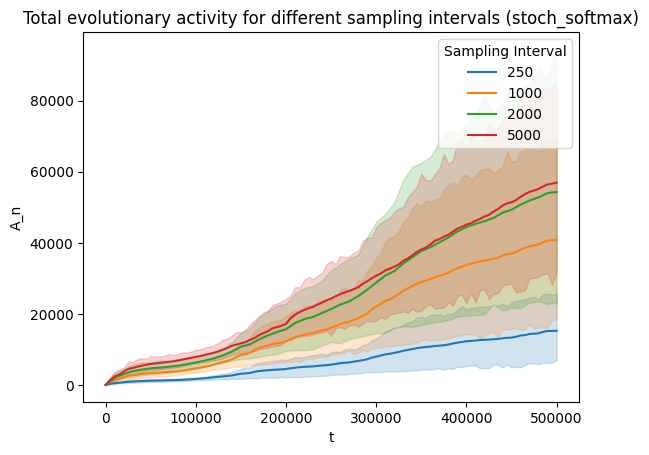

In [10]:
mixing_rules = [
    "avg",
    "softmax",
    "stoch",
    "stoch_gene_wise",
    "dot",
    "stoch_softmax",
    "stoch_softmax_gene_wise",
    "negotiate",
]


ea_srate1 = get_ea_data("results/srate1", mixing_rules)
ea_srate1.insert(2, "Sampling Interval", 250)
ea_srate4 = get_ea_data("results/srate4", mixing_rules)
ea_srate4.insert(2, "Sampling Interval", 1000)
ea_srate8 = get_ea_data("results/srate8", mixing_rules)
ea_srate8.insert(2, "Sampling Interval", 2000)
ea_srate20 = get_ea_data("results/srate20", mixing_rules)
ea_srate20.insert(2, "Sampling Interval", 5000)
ea_data = pd.concat([ea_srate1, ea_srate4, ea_srate8, ea_srate20])  


sns.lineplot(data=ea_data[(ea_data["t"]%5000==0) & (ea_data["Mixing rule"]=="stoch")], x="t", y="A_n",hue="Sampling Interval", palette="tab10")
plt.title("Total evolutionary activity for different sampling intervals (stoch)")
plt.savefig("ea_stoch.png", dpi=300, bbox_inches='tight')
plt.figure()
sns.lineplot(data=ea_data[(ea_data["t"]%5000==0) & (ea_data["Mixing rule"]=="stoch_softmax")&(ea_data["Beta"] == 100)],x="t", y="A_n",hue="Sampling Interval", palette="tab10")
plt.title("Total evolutionary activity for different sampling intervals (stoch_softmax)")
plt.savefig("ea_stoch_softmax.png", dpi=300, bbox_inches='tight')

<Axes: xlabel='Sampling Interval', ylabel='A_n'>

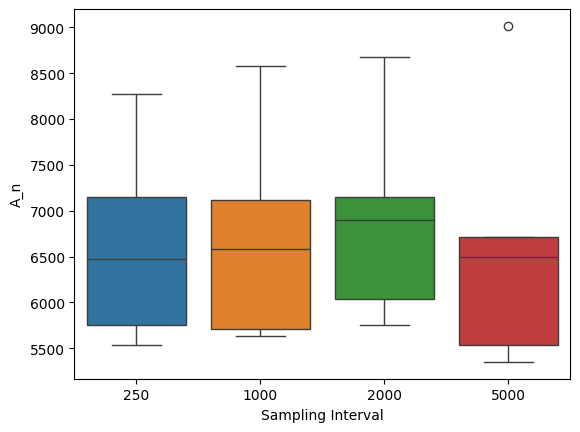

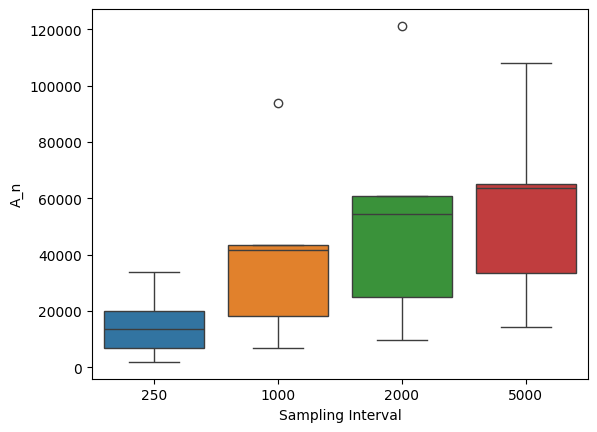

In [11]:
sns.boxplot(data=ea_data[(ea_data["t"] == 500000)&(ea_data["Mixing rule"] == 'stoch')], y="A_n", x="Sampling Interval", palette="tab10")
plt.figure()
sns.boxplot(data=ea_data[(ea_data["t"] == 500000)&(ea_data["Mixing rule"] == 'stoch_softmax')&(ea_data["Beta"] == 100)], y="A_n", x="Sampling Interval", palette="tab10")

['stoch_softmax_gene_wise' 'softmax' 'stoch_softmax' 'negotiate'
 'stoch_gene_wise' 'stoch' 'avg' 'dot']


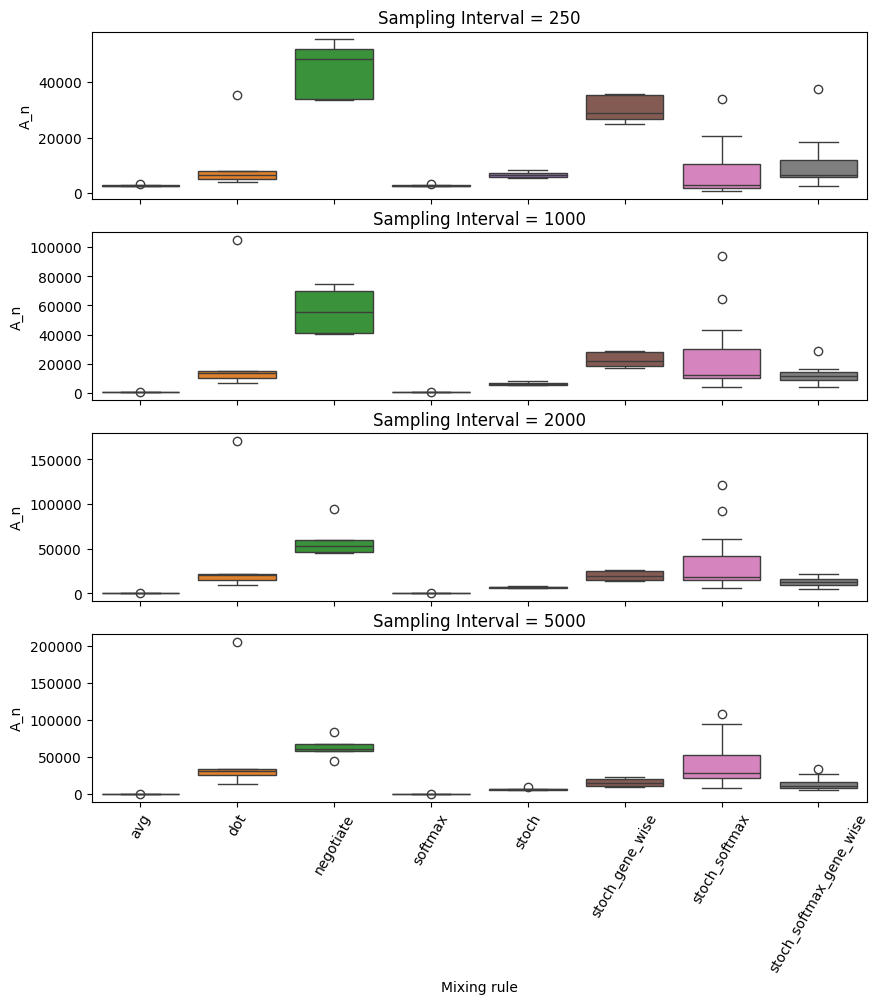

In [12]:

fig, axs = plt.subplots(4, 1, sharex=True, figsize=(10, 10))
#fig.subplots_adjust(hspace=0)
final_ea = ea_data[(ea_data["t"] == 500000)]
print(final_ea["Mixing rule"].unique())
final_ea = final_ea.sort_values("Mixing rule")
sns.boxplot(data=final_ea[final_ea["Sampling Interval"] == 250], x="Mixing rule", y="A_n", palette="tab10", ax=axs[0])
axs[0].set_title("Sampling Interval = 250")
#use same colors for all plots


sns.boxplot(data=final_ea[final_ea["Sampling Interval"] == 1000], x="Mixing rule", y="A_n", palette="tab10", ax=axs[1])
axs[1].set_title("Sampling Interval = 1000")
sns.boxplot(data=final_ea[final_ea["Sampling Interval"] == 2000], x="Mixing rule", y="A_n", palette="tab10", ax=axs[2])
axs[2].set_title("Sampling Interval = 2000")
sns.boxplot(data=final_ea[final_ea["Sampling Interval"] == 5000], x="Mixing rule", y="A_n", palette="tab10", ax=axs[3])
axs[3].set_title("Sampling Interval = 5000")

plt.xticks(rotation=60)
plt.savefig("ea_final_sampling.png", dpi=300, bbox_inches='tight')